# 08 · Space–time interaction: Knox test and near-repeat table

**Question.** Do bulletins that occur close in space also occur close in time more often than expected if the times were unrelated to the locations ("near repeats")? H0: event times are exchangeable over the fixed event locations (no space–time interaction).

**Method.** Knox (1964) statistic: the number of event pairs that are within a spatial distance band *and* a temporal band. Inference by **permuting the event dates over the fixed locations** (Mantel 1967; the Monte Carlo Knox test). The band table — distance bands [0, 100], (100, 200], (200, 400], (400, 800] m × time bands [0, 7], (7, 14], (14, 30], (30, 60] days — follows the near-repeat layout of Johnson & Bowers (2004, *British Journal of Criminology* 44(1)) and Ratcliffe's Near Repeat Calculator: per cell, **Knox ratio = observed pairs / mean over permutations** and one-sided pseudo p = (r + 1)/(P + 1), r = permutations with a count ≥ the observed one.

**Libraries.**
1. `pointpats.spacetime.Knox` (PySAL; Rogerson 2001 formulation) — the global Knox test for one *cumulative* threshold pair (distance ≤ δ, time ≤ τ), with a Poisson p and a permutation p.
2. pointpats has no banded (near-repeat) table and its permutation loop is pure Python over neighbour sets (memory and time grow with the number of pairs: ~3.6 s for 10 permutations of 5,000 events at δ = 800 m, τ = 60 d), so the band table is computed in a short, visible numpy cell (`scipy.spatial.cKDTree.query_pairs` for the spatial pairs, then permutations of the dates). That cell is checked against pointpats on a common subsample: same observed counts, same expected counts.

**Citations.** Knox, E.G. (1964). The detection of space-time interactions. *Applied Statistics* 13(1). Mantel, N. (1967). The detection of disease clustering and a generalized regression approach. *Cancer Research* 27(2). Johnson, S.D. & Bowers, K.J. (2004). The stability of space-time clusters of burglary. *BJC* 44(1). Ratcliffe, J.H. (2009). *Near Repeat Calculator* v1.3, Temple University / NIJ. Rogerson, P.A. (2001). *Statistical Methods for Geography*. Sage. Kulldorff, M. & Hjalmars, U. (1999). The Knox method and other tests for space-time interaction. *Biometrics* 55(2).

**Data.** `crime.data.load_points(group)`; time = occurrence **date** in whole days since 2022-01-01 (the hour is missing on part of the bulletins); EPSG:31983 metres.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pointpats
from matplotlib.colors import TwoSlopeNorm
from pointpats.spacetime import Knox
from scipy.spatial import cKDTree
from statsmodels.stats.multitest import multipletests

from crime.core.config import NOTEBOOK_OUTPUTS_DIR
from crime.data import GROUPS, load_points

OUT = NOTEBOOK_OUTPUTS_DIR / "08_knox"
OUT.mkdir(parents=True, exist_ok=True)

SEED = 20251031
S_EDGES = [100, 200, 400, 800]        # metres: [0,100], (100,200], (200,400], (400,800]
T_EDGES = [7, 14, 30, 60]             # days:   [0,7], (7,14], (14,30], (30,60]
S_LABELS = ["0–100 m", "100–200 m", "200–400 m", "400–800 m"]
T_LABELS = ["0–7 d", "8–14 d", "15–30 d", "31–60 d"]
P = 999                               # permutations, band table
N_MAX = 40_000                        # events per group for the band table (seeded subsample above this)
N_CHECK = 5_000                       # subsample for the pointpats cross-check
P_CHECK = 99                          # pointpats permutations in the cross-check
ALPHA = 0.05
print("pointpats", pointpats.__version__)

GROUP_LABEL = {"all": "All groups", "property": "Property", "bodily_harm": "Bodily harm",
               "traffic": "Traffic", "drug": "Drug", "violent": "Violent"}
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

def save(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

pts = load_points("all")
DAY0 = pd.Timestamp("2022-01-01")
events = {}
for g in GROUPS:
    p = pts if g == "all" else pts[pts["group"] == g]
    events[g] = (np.column_stack([p.geometry.x.to_numpy(), p.geometry.y.to_numpy()]),
                 (p["date"] - DAY0).dt.days.to_numpy().astype(np.int32))
pd.Series({g: len(v[1]) for g, v in events.items()}, name="events")

pointpats 2.6.0


all            107859
property        90436
bodily_harm      6590
traffic          6302
drug             4032
violent           499
Name: events, dtype: int64

## 1. The band table (visible implementation)

For n events with coordinates $s_i$ and day numbers $t_i$:

1. all unordered pairs with $\lVert s_i - s_j \rVert \le 800$ m (`cKDTree.query_pairs(800)`), each assigned a distance band; a separate band code marks pairs at **exactly the same coordinate** (distance 0, stacked geocodes), which belong to the 0–100 m band but are also reported on their own;
2. observed table: count of pairs in each (distance band, time band $|t_i - t_j|$) cell;
3. P = 999 permutations: shuffle the vector $t$ over the fixed locations (one `rng.permutation` per draw), recount;
4. Knox ratio = observed / mean of the permuted counts; pseudo p = (#permuted ≥ observed + 1)/(P + 1), one-sided (excess of close pairs); BH correction across the 16 cells of a group (statsmodels `multipletests(method="fdr_bh")`), reported next to the raw p.

Bands are closed on the right ($d \le 100$ → first band; $|Δt| \le 7$ → first band), as in pointpats (`KDTree.query_ball_tree` uses ≤).

In [2]:
def band_pairs(xy, max_d=S_EDGES[-1]):
    """Unordered pairs within max_d metres and their distance-band code: 0 = same coordinate, 1..4 = S_EDGES bands."""
    pairs = cKDTree(xy).query_pairs(max_d, output_type="ndarray").astype(np.int32)
    d = np.hypot(*(xy[pairs[:, 0]] - xy[pairs[:, 1]]).T)
    code = (np.searchsorted(S_EDGES, d, side="left") + 1).astype(np.int8)
    code[d == 0] = 0
    return pairs, code

T_LUT = np.searchsorted(T_EDGES, np.arange(0, 4000), side="left").astype(np.int8)   # |dt| days -> 0..3, 4 = beyond 60 d
N_S, N_T = len(S_EDGES) + 1, len(T_EDGES) + 1

def band_counts(pairs, scode, t):
    """(distance code 0..4) x (time band 0..4) pair counts for day vector t."""
    tb = T_LUT[np.abs(t[pairs[:, 0]] - t[pairs[:, 1]])]
    return np.bincount(scode.astype(np.int16) * N_T + tb, minlength=N_S * N_T).reshape(N_S, N_T)

def collapse(tab):
    """Merge the same-coordinate row into the 0-100 m band and drop the 'beyond 60 d' column -> 4 x 4."""
    t = tab[1:, :len(T_EDGES)].copy()
    t[0] += tab[0, :len(T_EDGES)]
    return t

## 2. Cross-check against `pointpats.spacetime.Knox`

On a seeded 5,000-event subsample of *all* groups, for every cumulative threshold pair (δ ∈ {100, 200, 400, 800} m, τ ∈ {7, 14, 30, 60} d): pointpats' observed space–time pair count `nst` and expected count (`expected[0, 0]` = NS·NT / pairs) must equal the cumulative sums of the band table above. pointpats' Poisson p and permutation p (99 permutations) are reported as the library's own test of the cumulative hypothesis.

In [3]:
rng = np.random.default_rng(SEED)
xy_all, t_all = events["all"]
idx = rng.choice(len(t_all), N_CHECK, replace=False)
xy_c, t_c = xy_all[idx], t_all[idx]
pairs_c, code_c = band_pairs(xy_c)
obs_c = collapse(band_counts(pairs_c, code_c, t_c))
cum_obs = obs_c.cumsum(axis=0).cumsum(axis=1)       # distance <= delta and time <= tau

rows = []
t0 = time.time()
np.random.seed(SEED)                                  # pointpats permutes with numpy's global RNG
for i, delta in enumerate(S_EDGES):
    for j, tau in enumerate(T_EDGES):
        k = Knox(xy_c, t_c.reshape(-1, 1).astype(float), delta=delta, tau=tau, permutations=P_CHECK)
        rows.append({"delta_m": delta, "tau_days": tau, "pointpats_nst": k.nst, "notebook_nst": int(cum_obs[i, j]),
                     "pointpats_expected": k.expected[0, 0], "pointpats_ratio_obs_exp": k.nst / k.expected[0, 0],
                     "pointpats_p_poisson": k.p_poisson, "pointpats_p_sim": k.p_sim})
check = pd.DataFrame(rows)
# expected under independence from the notebook's counts: NS * NT / pairs
n_c = len(t_c); n_pairs = n_c * (n_c - 1) / 2
ns = np.array([(np.hypot(*(xy_c[pairs_c[:, 0]] - xy_c[pairs_c[:, 1]]).T) <= d).sum() for d in S_EDGES])
dt_all = np.abs(t_c[:, None] - t_c[None, :])[np.triu_indices(n_c, 1)]
nt = np.array([(dt_all <= tau).sum() for tau in T_EDGES]); del dt_all
check["notebook_expected"] = (ns[:, None] * nt[None, :] / n_pairs).ravel()
assert (check["pointpats_nst"] == check["notebook_nst"]).all()
assert np.allclose(check["pointpats_expected"], check["notebook_expected"])
print(f"pointpats cross-check passed in {time.time()-t0:.0f}s")
check.to_csv(OUT / "pointpats_knox_crosscheck.csv", index=False)
check.round(4)

pointpats cross-check passed in 219s


,delta_m,tau_days,pointpats_nst,notebook_nst,pointpats_expected,pointpats_ratio_obs_exp,pointpats_p_poisson,pointpats_p_sim,notebook_expected
0,100,7,229,229,141.6905,1.6162,0.0,0.01,141.6905
1,100,14,382,382,273.2368,1.3981,0.0,0.01,273.2368
2,100,30,724,724,572.9924,1.2635,0.0,0.01,572.9924
3,100,60,1261,1261,1124.8382,1.1211,0.0,0.01,1124.8382
4,200,7,530,530,387.3968,1.3681,0.0,0.01,387.3968
5,200,14,921,921,747.0583,1.2328,0.0,0.01,747.0583
6,200,30,1799,1799,1566.6221,1.1483,0.0,0.01,1566.6221
7,200,60,3325,3325,3075.4271,1.0812,0.0,0.01,3075.4271
8,400,7,1559,1559,1251.9195,1.2453,0.0,0.01,1251.9195
9,400,14,2783,2783,2414.2090,1.1528,0.0,0.01,2414.2090


## 3. Band tables per group

Groups with more than `N_MAX = 40,000` events (all: 107,859; property: 90,436) use a seeded uniform random subsample of 40,000 events: the number of pairs within 800 m grows with n² (~24 million pairs at 40,000 events; ~170 million at 107,859), which sets memory and the time per permutation. The other groups use every event. Subsampling keeps the exchangeability null valid but lowers power; Knox ratios are comparable across n because they are relative to the permutation mean.

In [4]:
results, tables = [], {}
for g in GROUPS:
    xy, t = events[g]
    rng = np.random.default_rng(SEED)
    n_total = len(t)
    if n_total > N_MAX:
        keep = rng.choice(n_total, N_MAX, replace=False)
        xy, t = xy[keep], t[keep]
    t0 = time.time()
    pairs, scode = band_pairs(xy)
    obs = band_counts(pairs, scode, t)
    perm_sum = np.zeros_like(obs, dtype=float)
    ge = np.zeros(obs.shape, dtype=int)            # permutations >= observed, per raw cell
    obs4 = collapse(obs); ge4 = np.zeros(obs4.shape, dtype=int); perm4_sum = np.zeros(obs4.shape)
    for _ in range(P):
        c = band_counts(pairs, scode, rng.permutation(t))
        perm_sum += c; ge += c >= obs
        c4 = collapse(c); perm4_sum += c4; ge4 += c4 >= obs4
    mean4 = perm4_sum / P
    p4 = (ge4 + 1) / (P + 1)
    p_bh = multipletests(p4.ravel(), method="fdr_bh")[1].reshape(p4.shape)
    tables[g] = {"ratio": obs4 / mean4, "p": p4, "p_bh": p_bh, "obs": obs4}
    for i in range(4):
        for j in range(4):
            results.append({"group": g, "n_events_used": len(t), "n_events_total": n_total,
                            "distance_band": S_LABELS[i], "time_band": T_LABELS[j],
                            "observed_pairs": int(obs4[i, j]), "mean_permuted_pairs": mean4[i, j],
                            "knox_ratio": obs4[i, j] / mean4[i, j], "p_perm": p4[i, j], "p_bh": p_bh[i, j]})
    # same-coordinate pairs on their own (distance 0) and the 0-100 m band without them
    m0, mexcl = perm_sum[0] / P, perm_sum[1] / P
    for j in range(4):
        results.append({"group": g, "n_events_used": len(t), "n_events_total": n_total,
                        "distance_band": "same coordinate (0 m)", "time_band": T_LABELS[j],
                        "observed_pairs": int(obs[0, j]), "mean_permuted_pairs": m0[j],
                        "knox_ratio": obs[0, j] / m0[j] if m0[j] > 0 else np.nan,
                        "p_perm": (ge[0, j] + 1) / (P + 1), "p_bh": np.nan})
        results.append({"group": g, "n_events_used": len(t), "n_events_total": n_total,
                        "distance_band": "0–100 m excl. same coordinate", "time_band": T_LABELS[j],
                        "observed_pairs": int(obs[1, j]), "mean_permuted_pairs": mexcl[j],
                        "knox_ratio": obs[1, j] / mexcl[j] if mexcl[j] > 0 else np.nan,
                        "p_perm": (ge[1, j] + 1) / (P + 1), "p_bh": np.nan})
    share0 = obs[0, :4].sum() / obs4[0].sum() if obs4[0].sum() else np.nan
    print(f"{g:12s} n={len(t):6d}/{n_total:6d}  pairs<=800m {len(pairs):>11,}  same-coordinate share of 0-100 m pairs "
          f"(<=60 d) {100*share0:5.1f}%  [{time.time()-t0:.0f}s]")
    del pairs, scode
knox = pd.DataFrame(results)
knox.to_csv(OUT / "knox_band_table.csv", index=False)

all          n= 40000/107859  pairs<=800m  23,246,582  same-coordinate share of 0-100 m pairs (<=60 d)  25.3%  [952s]


property     n= 40000/ 90436  pairs<=800m  26,335,800  same-coordinate share of 0-100 m pairs (<=60 d)  23.7%  [1144s]


bodily_harm  n=  6590/  6590  pairs<=800m     334,665  same-coordinate share of 0-100 m pairs (<=60 d)  52.1%  [13s]


traffic      n=  6302/  6302  pairs<=800m     235,089  same-coordinate share of 0-100 m pairs (<=60 d)  51.9%  [9s]


drug         n=  4032/  4032  pairs<=800m     359,020  same-coordinate share of 0-100 m pairs (<=60 d)  65.4%  [13s]
violent      n=   499/   499  pairs<=800m       1,666  same-coordinate share of 0-100 m pairs (<=60 d)  57.9%  [0s]


In [5]:
main = knox[knox["distance_band"].isin(S_LABELS)]
wide = main.pivot_table(index=["group", "distance_band"], columns="time_band", values="knox_ratio", sort=False)[T_LABELS]
wide.round(3)

time_band                  0–7 d  8–14 d  15–30 d  31–60 d
group       distance_band                                 
all         0–100 m        1.481   1.162    1.114    1.097
            100–200 m      1.130   1.017    1.023    1.005
            200–400 m      1.096   1.010    1.017    1.003
            400–800 m      1.051   1.002    1.012    1.010
property    0–100 m        1.513   1.134    1.108    1.081
            100–200 m      1.135   1.017    1.019    1.006
            200–400 m      1.086   1.021    1.021    1.006
            400–800 m      1.053   1.017    1.016    1.012
bodily_harm 0–100 m        2.399   1.408    1.195    1.125
            100–200 m      1.093   1.025    1.036    0.989
            200–400 m      1.072   1.006    1.021    0.991
            400–800 m      0.992   1.000    0.997    0.997
traffic     0–100 m        1.647   1.229    1.219    1.156
            100–200 m      1.041   0.934    1.000    0.967
            200–400 m      1.063   0.993    0.947    0.999
            400–800 m      1.075   0.991    1.023    0.998
drug        0–100 m        1.777   1.396    1.395    1.415
            100–200 m      1.042   1.024    1.020    0.980
            200–400 m      1.041   1.004    1.010    0.986
            400–800 m      1.012   0.985    0.990    0.992
violent     0–100 m        4.200   1.498    1.067    1.592
            100–200 m      1.004   0.000    1.453    0.262
            200–400 m      0.987   1.881    1.090    1.084
            400–800 m      1.004   0.766    1.073    0.836

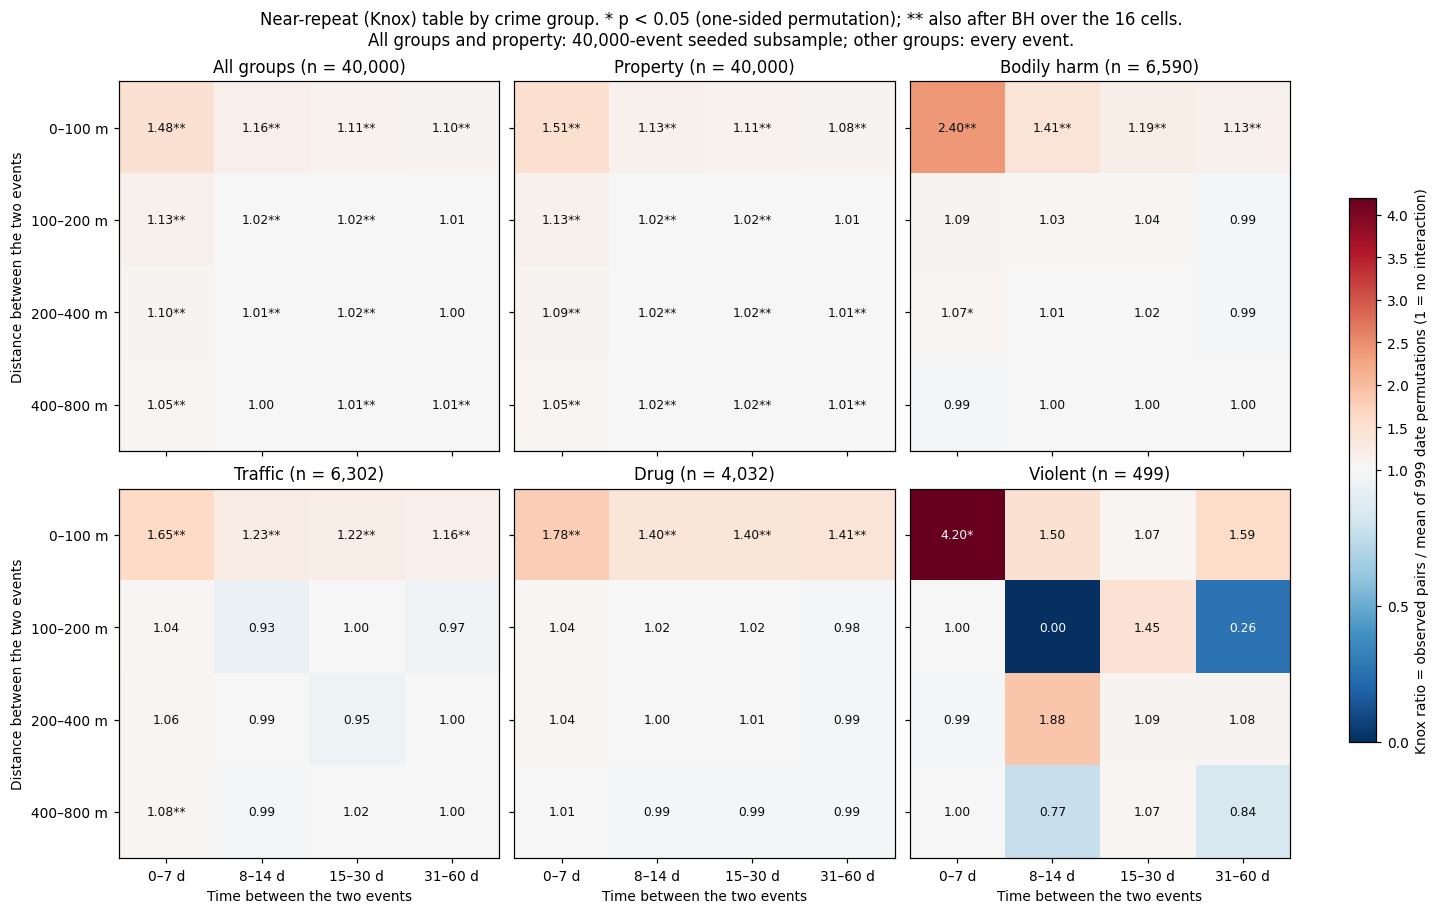

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8.2), sharex=True, sharey=True, layout="constrained")
vals = np.concatenate([tables[g]["ratio"].ravel() for g in GROUPS])
vmax = max(1.05, np.nanmax(vals)); vmin = min(0.95, np.nanmin(vals))
nrm = TwoSlopeNorm(vcenter=1.0, vmin=vmin, vmax=vmax)
for ax, g in zip(axes.flat, GROUPS):
    tb = tables[g]
    im = ax.imshow(tb["ratio"], cmap="RdBu_r", norm=nrm, aspect="auto")
    for i in range(4):
        for j in range(4):
            mark = "**" if tb["p_bh"][i, j] < ALPHA else ("*" if tb["p"][i, j] < ALPHA else "")
            r = tb["ratio"][i, j]
            ax.text(j, i, f"{r:.2f}{mark}", ha="center", va="center", fontsize=8,
                    color="white" if (r > 1 + 0.55 * (vmax - 1) or r < 1 - 0.55 * (1 - vmin)) else "#0b0b0b")
    ax.set_xticks(range(4), T_LABELS); ax.set_yticks(range(4), S_LABELS)
    n_used = main.loc[main["group"] == g, "n_events_used"].iat[0]
    ax.set_title(f"{GROUP_LABEL[g]} (n = {n_used:,})")
for ax in axes[1]:
    ax.set_xlabel("Time between the two events")
for ax in axes[:, 0]:
    ax.set_ylabel("Distance between the two events")
cb = fig.colorbar(im, ax=axes, shrink=0.7)
cb.set_label("Knox ratio = observed pairs / mean of 999 date permutations (1 = no interaction)")
fig.suptitle("Near-repeat (Knox) table by crime group. * p < 0.05 (one-sided permutation); ** also after BH over the 16 cells.\n"
             "All groups and property: 40,000-event seeded subsample; other groups: every event.")
save(fig, "knox_heatmap")

In [7]:
same = knox[knox["distance_band"].isin(["same coordinate (0 m)", "0–100 m excl. same coordinate"])]
same_w = same.pivot_table(index=["group", "distance_band"], columns="time_band", values="knox_ratio", sort=False)[T_LABELS]
same_w.round(3)

time_band                                  0–7 d  8–14 d  15–30 d  31–60 d
group       distance_band                                                 
all         same coordinate (0 m)          2.413   1.738    1.588    1.403
            0–100 m excl. same coordinate  1.276   1.035    1.009    1.029
property    same coordinate (0 m)          2.388   1.648    1.545    1.415
            0–100 m excl. same coordinate  1.334   1.029    1.018    1.012
bodily_harm same coordinate (0 m)          4.459   2.030    1.612    1.396
            0–100 m excl. same coordinate  1.219   1.054    0.957    0.970
traffic     same coordinate (0 m)          2.326   1.591    1.639    1.422
            0–100 m excl. same coordinate  1.194   0.987    0.939    0.978
drug        same coordinate (0 m)          2.840   2.134    1.939    1.877
            0–100 m excl. same coordinate  0.854   0.756    0.924    1.013
violent     same coordinate (0 m)          9.680   0.000    1.862    2.102
            0–100 m excl. same coordinate  1.097   2.440    0.576    1.281

## Findings

In [8]:
for g in GROUPS:
    tb = tables[g]
    sig = int((tb["p_bh"] < ALPHA).sum())
    print(f"{g:12s} ratio[0-100 m, 0-7 d] = {tb['ratio'][0,0]:.3f} (p {tb['p'][0,0]:.3f}, obs {tb['obs'][0,0]:,});  "
          f"max ratio {tb['ratio'].max():.3f};  cells significant after BH: {sig}/16")
    s = same[(same.group == g) & (same.time_band == T_LABELS[0])].set_index("distance_band")["knox_ratio"]
    print(f"{'':12s} 0-7 d: same-coordinate ratio {s.iloc[0]:.3f}, 0-100 m excl. same coordinate {s.iloc[1]:.3f}")

all          ratio[0-100 m, 0-7 d] = 1.481 (p 0.001, obs 12,679);  max ratio 1.481;  cells significant after BH: 13/16
             0-7 d: same-coordinate ratio 2.413, 0-100 m excl. same coordinate 1.276
property     ratio[0-100 m, 0-7 d] = 1.513 (p 0.001, obs 14,931);  max ratio 1.513;  cells significant after BH: 15/16
             0-7 d: same-coordinate ratio 2.388, 0-100 m excl. same coordinate 1.334
bodily_harm  ratio[0-100 m, 0-7 d] = 2.399 (p 0.001, obs 390);  max ratio 2.399;  cells significant after BH: 4/16
             0-7 d: same-coordinate ratio 4.459, 0-100 m excl. same coordinate 1.219
traffic      ratio[0-100 m, 0-7 d] = 1.647 (p 0.001, obs 313);  max ratio 1.647;  cells significant after BH: 5/16
             0-7 d: same-coordinate ratio 2.326, 0-100 m excl. same coordinate 1.194
drug         ratio[0-100 m, 0-7 d] = 1.777 (p 0.001, obs 894);  max ratio 1.777;  cells significant after BH: 4/16
             0-7 d: same-coordinate ratio 2.840, 0-100 m excl. same coordinat

_Written from the numbers printed above (rerun → recheck; every random draw is seeded)._

- **pointpats agreement.** On a 5,000-event subsample of all groups, the notebook's pair counts equal `pointpats.spacetime.Knox`'s observed space–time pairs and its expected counts (NS·NT / pairs) at all 16 cumulative thresholds. pointpats' observed/expected ratio runs from 1.04 (≤ 800 m, ≤ 60 d) to 1.62 (≤ 100 m, ≤ 7 d), with Poisson p ≈ 0 and permutation p = 0.01 everywhere (the floor for 99 permutations).
- **Near repeats are a 0–100 m, first-week effect.** Knox ratio at 0–100 m × 0–7 d: all groups 1.48, property 1.51, bodily harm 2.40, traffic 1.65, drug 1.78 (all p = 0.001, significant after BH), violent 4.20 (6 pairs vs ≈ 1.4 expected, p = 0.004, not significant after BH). The ratio decays with time (all: 1.48 → 1.16 → 1.11 → 1.10 across the time bands at 0–100 m) and with distance (all, 0–7 d: 1.48 → 1.13 → 1.10 → 1.05). Beyond 100 m no ratio exceeds 1.14 for any group except violent, whose sparse cells (0–34 pairs each) swing from 0 to 1.9 and are not significant.
- **Significance vs size.** After BH over the 16 cells: all 13/16, property 15/16, bodily harm 4/16, traffic 5/16, drug 4/16, violent 0/16. For all and property, excesses of only 1–2 % (ratios 1.01–1.02) are significant with millions of pairs; the size of the ratio, not the p-value, is the informative part there.
- **Stacked geocodes drive much of the closest band.** Pairs at exactly the same coordinate are 25 % (all), 24 % (property), 52 % (bodily harm), 52 % (traffic), 65 % (drug) and 58 % (violent) of the 0–100 m pairs within 60 days, and they carry the largest ratios (0–7 d: all 2.41, property 2.39, bodily harm 4.46, traffic 2.33, drug 2.84). Excluding them, the 0–100 m × 0–7 d ratio falls to 1.28 (all), 1.33 (property), 1.22 (bodily harm, p = 0.019) and 1.19 (traffic, p = 0.029), and for **drug it drops below 1 (0.85, p = 0.99)**: the drug near-repeat signal is entirely same-coordinate repeats; property, all, bodily harm and traffic keep a smaller near-but-not-identical-place excess in the first week.
- **Caveats.** Same coordinate can mean the same address (repeat victimisation) or several addresses geocoded to one street point, which this test cannot tell apart. Background shifts in where crime is recorded over 2022–2025 (e.g. the rising drug series, `02_stl`) can produce apparent interaction (Kulldorff & Hjalmars 1999), more so at the longer time bands. The all / property tables come from a 40,000-event subsample.